# CodeGuard AI · Experiment 07: Does retrieval find the right security guidance?

**Goal:** before trusting AI explanations, check that the retriever hands the language model the *right* documents.

**Steps**
1. Describe the knowledge base
2. Build a set of real findings to query with
3. Define "relevant" and the metrics
4. Compare three retrieval settings: semantic only, + CWE boost, + CWE and rule boost
5. Look at failures

In [1]:
import json
import sys
import time
import tempfile
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, str(Path("..").resolve()))
from codeguard.pipeline import scan, bandit_to_findings
from codeguard.rag import retriever
from codeguard.scanner.static_analyzer import run_bandit_dir

store = retriever.load_store()
print(json.dumps(store.info, indent=2))

{
  "built": "2026-10-15",
  "embedding_model": "sentence-transformers/all-MiniLM-L6-v2",
  "documents": {
    "cwe": 939,
    "owasp": 22,
    "bandit": 72
  },
  "chunks": {
    "cwe": 2584,
    "owasp": 643,
    "bandit": 93
  },
  "sources": {
    "cwe": "MITRE Common Weakness Enumeration (CWE) v4.15",
    "owasp": "22 cheat sheets, CC BY-SA 4.0",
    "bandit": "Bandit rule documentation (from the installed bandit package)"
  }
}


## Step 1: The knowledge base

| Source | What it gives the model |
|---|---|
| MITRE CWE v4.15 | Authoritative definition, consequences and mitigations of each weakness type |
| OWASP Cheat Sheets (22) | Practical defensive guidance and code-level advice |
| Bandit rule docs | What each rule detects and why |

In [2]:
lengths = pd.Series([len(c.text) for c in store.chunks])
kinds = pd.Series([c.kind for c in store.chunks])
print(lengths.groupby(kinds.values).describe()[["count", "50%", "max"]].round(0))

         count     50%     max
bandit    93.0  1015.0  1500.0
cwe     2584.0   369.0  1500.0
owasp    643.0   692.0  1500.0


## Step 2: Queries = real Bandit findings

Two sources of findings:
- the hand-written **vulnerable fixtures** (12 files);
- **real-world code**: the vulnerable versions of the methods in the CVEfixes v2 test set (Experiment 05b), scanned with Bandit. This gives findings from real projects, not just textbook examples.

In [3]:
queries = []
for path in sorted(Path("../tests/fixtures/vulnerable").glob("*.py")):
    for f in scan(path.read_text(), path.name, use_ml=False).findings:
        if not f.rule_id.startswith("B4"):          # import-only warnings carry little content
            queries.append(("fixture", f))

raw = pd.read_csv("../datasets/processed/python_functions.csv")
with tempfile.TemporaryDirectory() as tmp:
    sample = raw[raw["target"] == 1].sample(600, random_state=42)
    texts = {}
    for i, code_text in enumerate(sample["func"]):
        p = Path(tmp) / f"m{i}.py"
        p.write_text(code_text, encoding="utf-8")
        texts[p.name] = code_text
    report = run_bandit_dir(Path(tmp))
    by_file = {}
    for issue in report.issues:
        by_file.setdefault(Path(issue["filename"]).name, []).append(issue)
for name, issues in by_file.items():
    for f in bandit_to_findings(issues, texts[name], name):
        if not f.rule_id.startswith("B4") and f.cwe:
            queries.append(("cvefixes", f))

print("Queries:", Counter(src for src, _ in queries))
print("Rules:", Counter(f.rule_id for _, f in queries).most_common(12))

Queries: Counter({'cvefixes': 163, 'fixture': 12})
Rules: [('B101', 114), ('B608', 11), ('B106', 9), ('B113', 8), ('B108', 8), ('B307', 4), ('B602', 3), ('B110', 3), ('B102', 2), ('B306', 2), ('B605', 2), ('B311', 2)]


## Step 3: What counts as relevant?

For a finding with CWE *c* and rule *r*, a retrieved document is **relevant** if it is tagged with CWE *c* (the CWE entry itself, or an OWASP cheat sheet mapped to that CWE in `knowledge_base/sources.yaml`) or if it is the Bandit documentation for rule *r*.

Metrics, computed per document (the retriever returns at most one chunk per document):
- **Hit@k:** at least one relevant document in the top *k*.
- **MRR:** 1 / rank of the first relevant document (higher is better).
- **Guidance@4:** an OWASP cheat sheet (practical advice, not only a definition) is among the four passages the model receives.

> **Be aware of circularity.** The boosted settings use the same CWE and rule tags that define relevance, so they are *expected* to score well. The **semantic-only** setting is the fair test of the embeddings; the boosted setting shows what the system actually does.

In [4]:
def evaluate(boost_cwe: bool, boost_rule: bool, diverse: bool = False, k: int = 4):
    rows = []
    for src, f in queries:
        q = retriever.finding_query(f)
        passages = retriever.retrieve_for_text(q, store, k=k, cwe=f.cwe if boost_cwe else None,
                                               rule_id=f.rule_id if boost_rule else None, diverse=diverse)
        relevant = [(f.cwe in p.chunk.cwe_ids) or (f.rule_id in p.chunk.rule_ids) for p in passages]
        first = next((i + 1 for i, r in enumerate(relevant) if r), None)
        rows.append({"source": src, "rule": f.rule_id, "cwe": f.cwe, "hit@1": bool(relevant[:1] and relevant[0]),
                     "hit@3": any(relevant[:3]), "hit@4": any(relevant), "rr": 1 / first if first else 0.0,
                     "guidance@4": any(p.chunk.kind == "owasp" for p in passages),
                     "top": passages[0].citation})
    return pd.DataFrame(rows)

settings_ = {"Semantic only": (False, False, False), "+ CWE boost": (True, False, False),
             "+ CWE and rule boost": (True, True, False), "+ boosts, diverse slots (used)": (True, True, True)}
start = time.time()
results = {name: evaluate(*flags) for name, flags in settings_.items()}
print(f"{len(queries) * 3} retrievals in {time.time() - start:.1f} s")
summary = pd.DataFrame({name: r[["hit@1", "hit@3", "hit@4", "rr", "guidance@4"]].mean() for name, r in results.items()}).T
summary = summary.rename(columns={"rr": "MRR"}).round(3)
summary

no_assert = [i for i, (_, f) in enumerate(queries) if f.rule_id != "B101"]
print(f"Without B101 (assert) findings, {len(no_assert)} queries:")
pd.DataFrame({name: r.iloc[no_assert][["hit@1", "hit@3", "rr", "guidance@4"]].mean() for name, r in results.items()}).T.round(3)

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

525 retrievals in 30.5 s
Without B101 (assert) findings, 61 queries:


,hit@1,hit@3,rr,guidance@4
Semantic only,0.754,0.918,0.832,0.066
+ CWE boost,1.000,1.000,1.000,0.770
+ CWE and rule boost,1.000,1.000,1.000,0.770
"+ boosts, diverse slots (used)",1.000,1.000,1.000,0.836


In [5]:
by_source = pd.concat({name: r.groupby("source")[["hit@1", "hit@3", "rr"]].mean() for name, r in results.items()}).round(3)
by_source

hit@1  hit@3     rr
                               source                       
Semantic only                  cvefixes  0.239  0.276  0.258
                               fixture   0.583  0.917  0.729
+ CWE boost                    cvefixes  1.000  1.000  1.000
                               fixture   1.000  1.000  1.000
+ CWE and rule boost           cvefixes  1.000  1.000  1.000
                               fixture   1.000  1.000  1.000
+ boosts, diverse slots (used) cvefixes  1.000  1.000  1.000
                               fixture   1.000  1.000  1.000

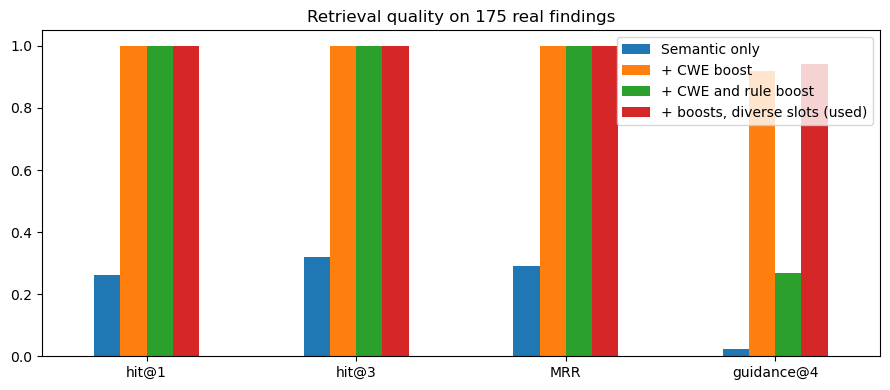

In [6]:
ax = summary[["hit@1", "hit@3", "MRR", "guidance@4"]].T.plot.bar(figsize=(9, 4), rot=0)
ax.set_ylim(0, 1.05)
ax.set_title(f"Retrieval quality on {len(queries)} real findings")
plt.tight_layout()
plt.savefig("../artifacts/figures/retrieval_eval.png", dpi=120)
plt.show()

## Step 5: Where does semantic-only retrieval fail?

In [7]:
sem = results["Semantic only"]
fails = sem[~sem["hit@3"]]
print(f"{len(fails)} of {len(sem)} findings had no relevant document in the semantic top 3")
fails.groupby(["rule", "cwe"]).size().sort_values(ascending=False).head(10)

119 of 175 findings had no relevant document in the semantic top 3


rule  cwe
B101  703    114
B110  703      3
B102  95       2
dtype: int64

In [8]:
per_rule = results["+ boosts, diverse slots (used)"].groupby("rule")[["hit@1", "guidance@4"]].mean()
per_rule.assign(n=results["Semantic only"].groupby("rule").size()).sort_values("n", ascending=False).round(2)

,hit@1,guidance@4,n
rule,,,
B101,1.0,1.0,114
B608,1.0,1.0,11
B106,1.0,1.0,9
B113,1.0,1.0,8
B108,1.0,0.0,8
B307,1.0,1.0,4
B602,1.0,1.0,3
B110,1.0,1.0,3
B102,1.0,1.0,2


In [9]:
Path("../artifacts/metrics/retrieval_results.json").write_text(json.dumps({
    "queries": int(len(queries)), "by_source": dict(Counter(s for s, _ in queries)),
    "summary": summary.reset_index(names="setting").to_dict(orient="records"),
    "embedding_model": store.info.get("embedding_model"), "chunks": len(store)}, indent=2))
print("Saved artifacts/metrics/retrieval_results.json")

Saved artifacts/metrics/retrieval_results.json


## Conclusion

175 real Bandit findings were used as queries: 12 from fixtures and 163 from the vulnerable versions of 600 CVEfixes methods. Each query returns 4 passages.

| Setting | Hit@1 | Hit@3 | MRR | OWASP guidance in top 4 |
|---|---|---|---|---|
| Semantic only | 0.263 | 0.320 | 0.290 | 0.023 |
| + CWE boost | 1.000 | 1.000 | 1.000 | 0.920 |
| + CWE and rule boost | 1.000 | 1.000 | 1.000 | 0.269 |
| **+ boosts, diverse slots (used)** | **1.000** | **1.000** | **1.000** | **0.943** |

1. **Semantic search alone is good on typical findings but fails on one big group.** Excluding the 114 `assert` findings (B101, CWE-703), semantic Hit@3 is 0.918. With them included it drops to 0.320, because "use of assert detected" shares no words with CWE-703's title ("Improper Check or Handling of Exceptional Conditions").
2. **Metadata boosts make retrieval reliable.** Every finding gets its own CWE entry or Bandit rule page first. This is partly by construction (relevance uses the same tags), which is why semantic-only is reported as the fair test of the embeddings.
3. **The rule boost alone crowded out practical advice** (OWASP in top 4 only 27%). Reserving one slot each for the Bandit page, the CWE entry and a CWE-tagged OWASP cheat sheet raised this to 94% without losing relevance. This **diverse** mode is what the app uses. It was chosen *on this evaluation*, so treat 0.943 as a development result.
4. **Gaps:** CWE-377 (insecure temporary files: B108, B306) has no mapped OWASP cheat sheet, so those findings get only the CWE entry and Bandit docs.

**Limits:** relevance is judged by tags, not by people; the query set is dominated by B101; one embedding model (all-MiniLM-L6-v2) was tested.